# Modelado - House Pricing

**Autor:** Roberto Farfan

Torneo de 6 modelos (regresión regularizada, ensambles y una red neuronal) para predecir `SalePrice`. Cada modelo se optimiza con `GridSearchCV` y validación cruzada K-Fold (k = 10), y el ganador se elige comparando su desempeño en el set de validación con el RMSE real (en dólares) y el RMSE normalizado al rango.

**Cómo se evita la fuga de datos:** el pipeline de features del notebook `2.0-rf-feature-engineering` se usa como una copia **sin ajustar** dentro de cada modelo, así que en cada fold de la validación cruzada las imputaciones, los límites de outliers, las transformaciones y el escalado se calculan solo con los datos de entrenamiento de ese fold. El set de validación no se usa hasta la comparación final.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import make_scorer, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import yaml

from house_pricing.config import MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR

2026-10-30 20:51:20.960 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing


## Carga de datos y división

Reproduce exactamente la división del notebook 2.0: elimina las 2 casas con `GrLivArea > 4000` y `SalePrice < 300000`, transforma el target con `log1p` y divide 80/20 con `random_state=42`. Se parte de los datos crudos (y no de `data/processed`) para que el pipeline de features se pueda reajustar dentro de cada fold. Al final se verifica que el set de validación coincide con el guardado en `data/processed`.

In [3]:
target = "SalePrice"

train = pd.read_csv(RAW_DATA_DIR / "train.csv", index_col="Id")
with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    model_features = yaml.safe_load(f)["MODEL_FEATURES"]

mask_outliers = (train["GrLivArea"] > 4000) & (train[target] < 300000)
train = train.loc[~mask_outliers]

X = train[model_features]
y = np.log1p(train[target]).rename("SalePrice_log")
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Verifica que la división es la misma del notebook 2.0
y_val_guardado = pd.read_csv(PROCESSED_DATA_DIR / "y_val.csv", index_col="Id")["SalePrice_log"]
assert X_val.index.equals(y_val_guardado.index), "El set de validación no coincide con el del notebook 2.0"

print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")

X_train: (1166, 30) | X_val: (292, 30)


## Pipeline de features, métrica y validación cruzada

- **Pipeline de features:** `clone` del pipeline guardado en `models/pipeline_fe.joblib` devuelve una copia con la misma configuración pero sin ajustar, que se vuelve a ajustar en cada fold.
- **Métrica:** RMSE real en dólares. Los modelos se entrenan con `SalePrice_log`, así que las predicciones se regresan a dólares con `expm1` antes de calcular el error. Las predicciones en escala log se limitan a [0, 15] para que una predicción extrema no desborde `expm1`.
- **RMSE normalizado al rango:** `RMSE real / (máx − mín de SalePrice en validación)`.
- **Validación cruzada:** K-Fold con k = 10, con mezcla aleatoria y semilla fija.

In [4]:
pipeline_fe = joblib.load(MODELS_DIR / "pipeline_fe.joblib")


def a_dolares(y_log):
    return np.expm1(np.clip(y_log, 0, 15))


def rmse_real(y_log_true, y_log_pred):
    return root_mean_squared_error(a_dolares(y_log_true), a_dolares(y_log_pred))


scorer_rmse_real = make_scorer(rmse_real, greater_is_better=False)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

precio_val = a_dolares(y_val)
rango_val = precio_val.max() - precio_val.min()
print(f"Rango de SalePrice en validación: {rango_val:,.0f}")

Rango de SalePrice en validación: 416,639


## Función de entrenamiento y evaluación

`entrenar_modelo` arma el pipeline completo (features + modelo), ejecuta `GridSearchCV` con K-Fold k = 10 y, con la mejor configuración (reentrenada con todo el set de entrenamiento), calcula:

- **RMSE de entrenamiento:** error sobre los mismos datos con que se entrenó.
- **RMSE de CV:** media y desviación estándar en los 10 folds.
- **RMSE de validación y RMSE normalizado:** error sobre datos que el modelo nunca vio.

Una brecha grande entre el RMSE de entrenamiento y el de CV o validación indica sobreajuste.

In [5]:
resultados = {}


def entrenar_modelo(nombre, modelo, grilla):
    pipeline = Pipeline([("features", clone(pipeline_fe)), ("modelo", modelo)])
    busqueda = GridSearchCV(pipeline, grilla, scoring=scorer_rmse_real, cv=kfold, n_jobs=-1)
    busqueda.fit(X_train, y_train)

    mejor = busqueda.best_estimator_
    idx = busqueda.best_index_
    rmse_folds = np.array([-busqueda.cv_results_[f"split{i}_test_score"][idx] for i in range(kfold.n_splits)])
    pred_val = mejor.predict(X_val)
    rmse_val = rmse_real(y_val, pred_val)

    resultados[nombre] = {
        "busqueda": busqueda,
        "pred_val": a_dolares(pred_val),
        "rmse_folds": rmse_folds,
        "rmse_train": rmse_real(y_train, mejor.predict(X_train)),
        "rmse_cv": rmse_folds.mean(),
        "rmse_cv_std": rmse_folds.std(),
        "rmse_val": rmse_val,
        "nrmse_val": rmse_val / rango_val,
    }

    configs = pd.DataFrame(busqueda.cv_results_["params"])
    configs["rmse_cv"] = -busqueda.cv_results_["mean_test_score"]
    print(f"{nombre}: {len(configs)} configuraciones probadas")
    print(f"Mejor configuración: {busqueda.best_params_}")
    print(
        f"RMSE train: {resultados[nombre]['rmse_train']:,.0f} | "
        f"RMSE CV: {resultados[nombre]['rmse_cv']:,.0f} ± {resultados[nombre]['rmse_cv_std']:,.0f} | "
        f"RMSE val: {rmse_val:,.0f} | NRMSE val: {resultados[nombre]['nrmse_val']:.4f}"
    )
    return configs.sort_values("rmse_cv").round(4)

## Modelo 1: Ridge

Regresión lineal con regularización L2: reduce los coeficientes para que el modelo no dependa demasiado de una sola variable. Se busca la fuerza de regularización `alpha`.

In [6]:
entrenar_modelo(
    "Ridge",
    Ridge(),
    {"modelo__alpha": [0.1, 1, 3, 10, 30, 100]},
)

Ridge: 6 configuraciones probadas
Mejor configuración: {'modelo__alpha': 30}
RMSE train: 25,180 | RMSE CV: 25,705 ± 4,622 | RMSE val: 23,652 | NRMSE val: 0.0568


,modelo__alpha,rmse_cv
4,30.0,25705.4278
3,10.0,25720.5760
2,3.0,25739.8804
1,1.0,25747.2623
0,0.1,25750.8924
5,100.0,25855.6328


## Modelo 2: Lasso

Regresión lineal con regularización L1: además de reducir coeficientes, puede llevar algunos a cero, lo que funciona como selección de variables. Se busca `alpha`.

In [7]:
entrenar_modelo(
    "Lasso",
    Lasso(max_iter=50000),
    {"modelo__alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01]},
)

Lasso: 5 configuraciones probadas
Mejor configuración: {'modelo__alpha': 0.0001}
RMSE train: 25,185 | RMSE CV: 25,759 ± 4,622 | RMSE val: 23,565 | NRMSE val: 0.0566


,modelo__alpha,rmse_cv
0,0.0001,25759.0711
1,0.0003,25777.0039
2,0.0010,25847.7619
3,0.0030,26021.8684
4,0.0100,26745.1749


## Modelo 3: ElasticNet

Combina las regularizaciones L1 y L2. Se busca la fuerza total (`alpha`) y la proporción de L1 (`l1_ratio`).

In [8]:
entrenar_modelo(
    "ElasticNet",
    ElasticNet(max_iter=50000),
    {
        "modelo__alpha": [0.0001, 0.001, 0.01],
        "modelo__l1_ratio": [0.2, 0.5, 0.8],
    },
)

ElasticNet: 9 configuraciones probadas
Mejor configuración: {'modelo__alpha': 0.0001, 'modelo__l1_ratio': 0.2}
RMSE train: 25,176 | RMSE CV: 25,753 ± 4,610 | RMSE val: 23,585 | NRMSE val: 0.0566


,modelo__alpha,modelo__l1_ratio,rmse_cv
0,0.0001,0.2,25752.5252
1,0.0001,0.5,25755.0014
2,0.0001,0.8,25757.4912
3,0.0010,0.2,25764.4526
4,0.0010,0.5,25794.0491
5,0.0010,0.8,25826.8804
6,0.0100,0.2,25891.8991
7,0.0100,0.5,26215.1219
8,0.0100,0.8,26527.8591


## Modelo 4: Random Forest

Ensamble de árboles de decisión entrenados en paralelo sobre muestras aleatorias; la predicción es el promedio de los árboles. Se busca la profundidad máxima, el mínimo de casas por hoja y la proporción de variables que considera cada división (valores más restrictivos reducen el sobreajuste).

In [9]:
entrenar_modelo(
    "RandomForest",
    RandomForestRegressor(n_estimators=300, random_state=42),
    {
        "modelo__max_depth": [None, 15],
        "modelo__min_samples_leaf": [1, 3],
        "modelo__max_features": [0.33, 1.0],
    },
)

RandomForest: 8 configuraciones probadas
Mejor configuración: {'modelo__max_depth': None, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 1}
RMSE train: 10,546 | RMSE CV: 26,716 ± 4,787 | RMSE val: 24,232 | NRMSE val: 0.0582


,modelo__max_depth,modelo__max_features,modelo__min_samples_leaf,rmse_cv
0,NaN,0.33,1,26715.6514
4,15.0,0.33,1,26832.8442
6,15.0,1.00,1,27547.6458
2,NaN,1.00,1,27560.7838
1,NaN,0.33,3,27833.2941
5,15.0,0.33,3,27889.3318
3,NaN,1.00,3,28183.3250
7,15.0,1.00,3,28188.1871


## Modelo 5: Gradient Boosting

Ensamble de árboles entrenados en secuencia, donde cada árbol corrige los errores de los anteriores. Se busca el número de árboles, la tasa de aprendizaje y la profundidad; `subsample=0.8` entrena cada árbol con el 80 % de los datos para reducir el sobreajuste.

In [10]:
entrenar_modelo(
    "GradientBoosting",
    GradientBoostingRegressor(subsample=0.8, random_state=42),
    {
        "modelo__n_estimators": [300, 600],
        "modelo__learning_rate": [0.03, 0.1],
        "modelo__max_depth": [2, 3],
    },
)

GradientBoosting: 8 configuraciones probadas
Mejor configuración: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 300}
RMSE train: 17,265 | RMSE CV: 25,338 ± 3,316 | RMSE val: 22,992 | NRMSE val: 0.0552


,modelo__learning_rate,modelo__max_depth,modelo__n_estimators,rmse_cv
2,0.03,3,300,25338.0387
3,0.03,3,600,25472.6873
1,0.03,2,600,25508.4638
0,0.03,2,300,26185.3685
4,0.10,2,300,26191.5199
6,0.10,3,300,26751.8680
5,0.10,2,600,26832.8770
7,0.10,3,600,27233.0159


## Modelo 6: Red neuronal (MLPRegressor)

Perceptrón multicapa. Se busca la arquitectura (capas ocultas y neuronas) y la regularización L2 (`alpha`). Para evitar sobreajuste usa `early_stopping`: separa el 10 % de los datos de entrenamiento del fold y detiene el entrenamiento cuando el error en esa parte deja de mejorar. El target se estandariza dentro del modelo (`TransformedTargetRegressor`), porque las redes neuronales entrenan mejor con salidas cercanas a 0.

In [11]:
entrenar_modelo(
    "MLP",
    TransformedTargetRegressor(
        regressor=MLPRegressor(max_iter=2000, early_stopping=True, random_state=42),
        transformer=StandardScaler(),
    ),
    {
        "modelo__regressor__hidden_layer_sizes": [(64,), (64, 32), (128, 64)],
        "modelo__regressor__alpha": [0.001, 0.1],
    },
)

MLP: 6 configuraciones probadas
Mejor configuración: {'modelo__regressor__alpha': 0.1, 'modelo__regressor__hidden_layer_sizes': (128, 64)}
RMSE train: 15,350 | RMSE CV: 26,533 ± 3,046 | RMSE val: 24,016 | NRMSE val: 0.0576


,modelo__regressor__alpha,modelo__regressor__hidden_layer_sizes,rmse_cv
5,0.100,"(128, 64)",26533.4969
2,0.001,"(128, 64)",26614.6965
3,0.100,"(64,)",27705.6242
0,0.001,"(64,)",27935.1409
4,0.100,"(64, 32)",27939.2320
1,0.001,"(64, 32)",28287.8056


## Resultados del torneo

Tabla comparativa de los 6 modelos con su mejor configuración, ordenada por RMSE en validación. La columna `brecha_train_cv` es la diferencia relativa entre el error de CV y el de entrenamiento: valores altos indican sobreajuste.

In [12]:
tabla = pd.DataFrame({
    nombre: {
        "rmse_train": r["rmse_train"],
        "rmse_cv": r["rmse_cv"],
        "rmse_cv_std": r["rmse_cv_std"],
        "rmse_val": r["rmse_val"],
        "nrmse_val": r["nrmse_val"],
    }
    for nombre, r in resultados.items()
}).T
tabla["brecha_train_cv"] = (tabla["rmse_cv"] - tabla["rmse_train"]) / tabla["rmse_cv"]
tabla = tabla.sort_values("rmse_val")
tabla.round({
    "rmse_train": 0, "rmse_cv": 0, "rmse_cv_std": 0,
    "rmse_val": 0, "nrmse_val": 4, "brecha_train_cv": 3,
})

,rmse_train,rmse_cv,rmse_cv_std,rmse_val,nrmse_val,brecha_train_cv
GradientBoosting,17265.0,25338.0,3316.0,22992.0,0.0552,0.319
Lasso,25185.0,25759.0,4622.0,23565.0,0.0566,0.022
ElasticNet,25176.0,25753.0,4610.0,23585.0,0.0566,0.022
Ridge,25180.0,25705.0,4622.0,23652.0,0.0568,0.020
MLP,15350.0,26533.0,3046.0,24016.0,0.0576,0.421
RandomForest,10546.0,26716.0,4787.0,24232.0,0.0582,0.605


## Comparación del torneo

- **Barras:** RMSE real y RMSE normalizado al rango en el set de validación (menor es mejor).
- **Boxplot:** RMSE de los 10 folds de la validación cruzada para la mejor configuración de cada modelo. Una caja angosta indica un modelo estable.

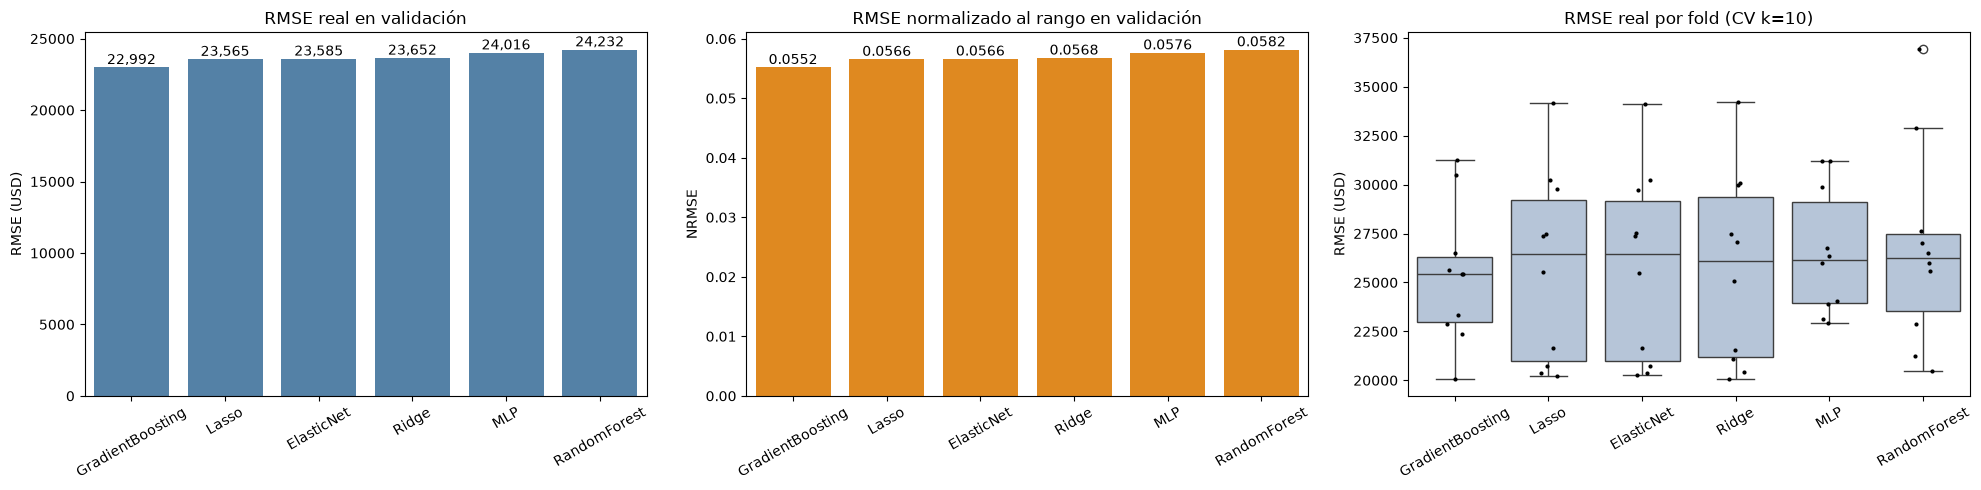

In [13]:
orden = tabla.index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.barplot(x=orden, y=tabla["rmse_val"], ax=axes[0], color="steelblue")
axes[0].set_title("RMSE real en validación")
axes[0].set_ylabel("RMSE (USD)")
for i, v in enumerate(tabla["rmse_val"]):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

sns.barplot(x=orden, y=tabla["nrmse_val"], ax=axes[1], color="darkorange")
axes[1].set_title("RMSE normalizado al rango en validación")
axes[1].set_ylabel("NRMSE")
for i, v in enumerate(tabla["nrmse_val"]):
    axes[1].text(i, v, f"{v:.4f}", ha="center", va="bottom")

folds = pd.DataFrame({nombre: resultados[nombre]["rmse_folds"] for nombre in orden})
sns.boxplot(data=folds, ax=axes[2], color="lightsteelblue")
sns.stripplot(data=folds, ax=axes[2], color="black", size=3)
axes[2].set_title("RMSE real por fold (CV k=10)")
axes[2].set_ylabel("RMSE (USD)")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Predicho vs real en validación

Para cada modelo, compara el precio predicho con el real en el set de validación (en dólares). Los puntos sobre la línea roja (y = x) son predicciones perfectas; si se abren en abanico o se curvan, el modelo se equivoca más en ciertos rangos de precio.

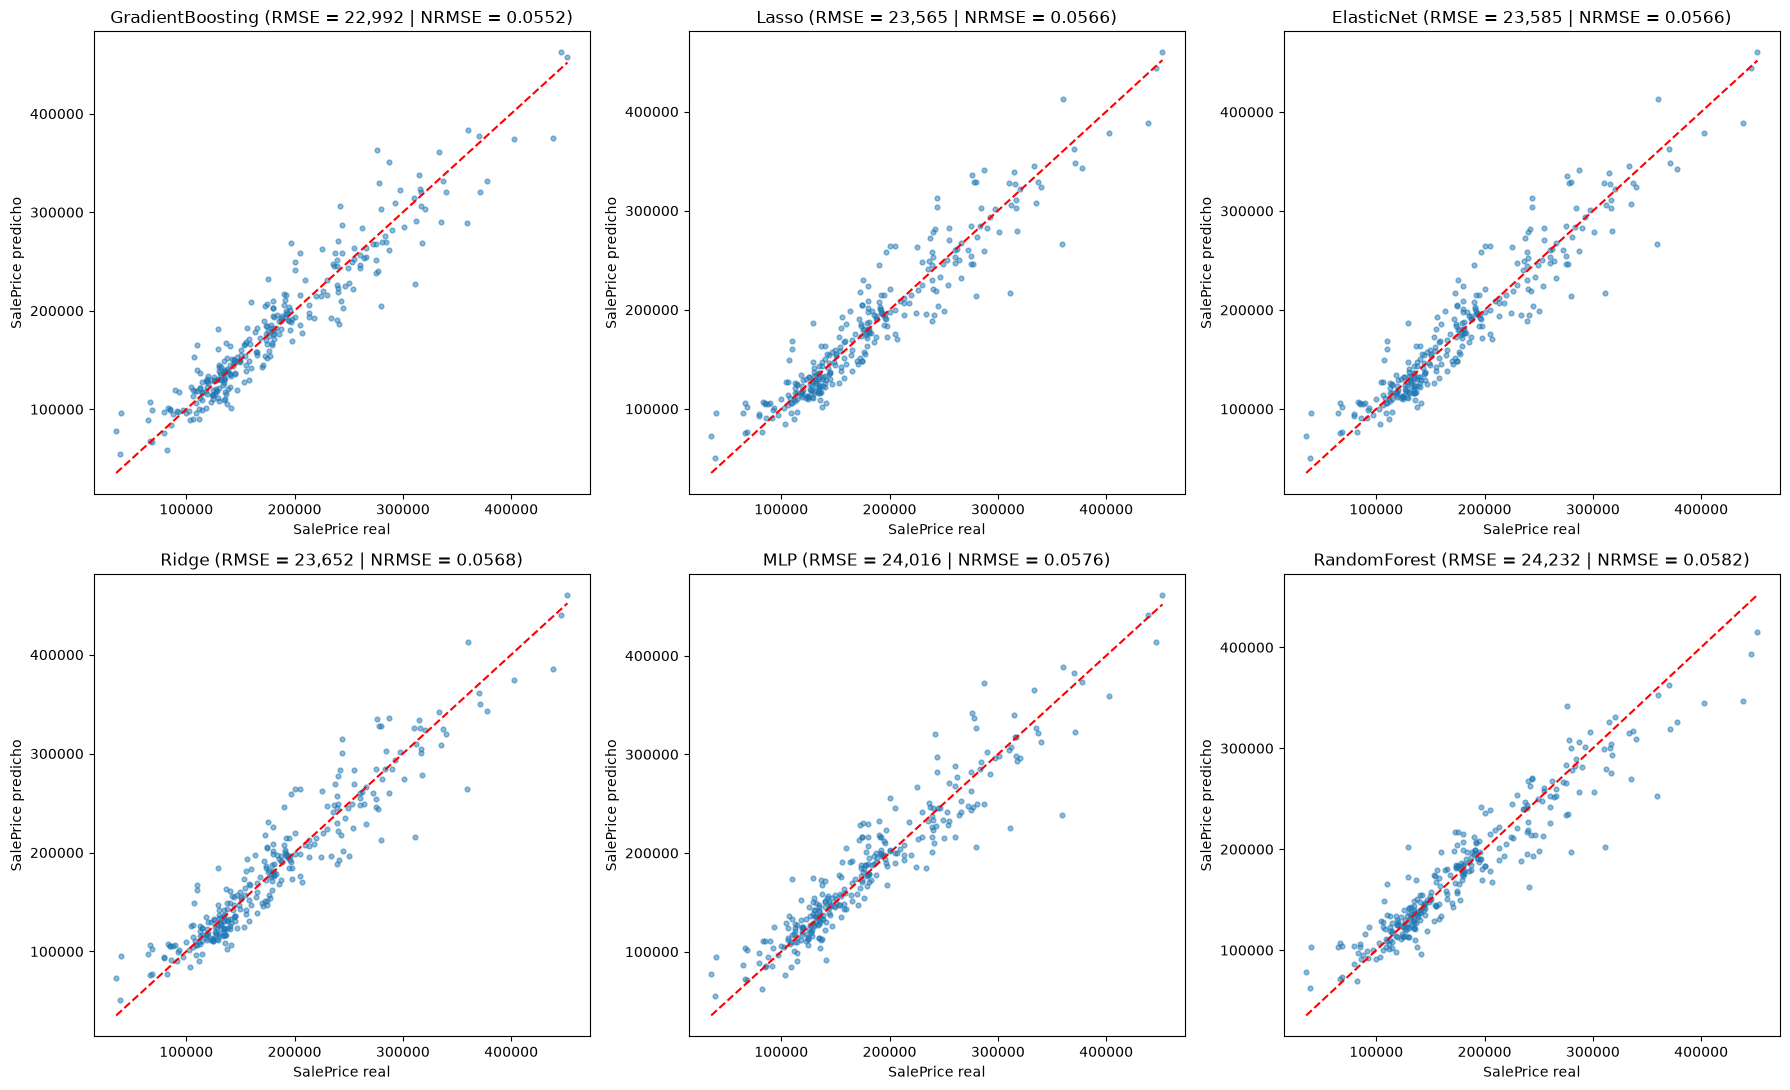

In [14]:
n_cols = 3
n_rows = int(np.ceil(len(orden) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5.5 * n_rows))
axes = axes.flatten()

limites = [precio_val.min(), precio_val.max()]
for ax, nombre in zip(axes, orden):
    r = resultados[nombre]
    ax.scatter(precio_val, r["pred_val"], alpha=0.5, s=12)
    ax.plot(limites, limites, color="red", linestyle="--")
    ax.set_title(f"{nombre} (RMSE = {r['rmse_val']:,.0f} | NRMSE = {r['nrmse_val']:.4f})")
    ax.set_xlabel("SalePrice real")
    ax.set_ylabel("SalePrice predicho")

for ax in axes[len(orden):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Modelo ganador

Selecciona el modelo con menor RMSE real en validación y guarda su pipeline completo (features + modelo, entrenado con el set de entrenamiento) en `models/` para usarlo en las predicciones.

In [15]:
ganador = tabla.index[0]
modelo_ganador = resultados[ganador]["busqueda"].best_estimator_

print(f"Modelo ganador: {ganador}")
print(f"Configuración: {resultados[ganador]['busqueda'].best_params_}")
print(f"RMSE val: {tabla.loc[ganador, 'rmse_val']:,.0f} | NRMSE val: {tabla.loc[ganador, 'nrmse_val']:.4f}")

ruta_modelo = MODELS_DIR / "modelo_ganador.joblib"
joblib.dump(modelo_ganador, ruta_modelo)
print(f"Guardado en: {ruta_modelo}")

Modelo ganador: GradientBoosting
Configuración: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 300}
RMSE val: 22,992 | NRMSE val: 0.0552
Guardado en: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing\models\modelo_ganador.joblib


## Pipeline de inferencia

Arma el pipeline final que recibe los datos **crudos** y devuelve el precio **en dólares**:

1. `seleccion`: toma solo las columnas de `MODEL_FEATURES` del CSV crudo.
2. `features`: el pipeline de ingeniería de características del notebook 2.0 (imputación, codificación, outliers, Yeo-Johnson y escalado).
3. `modelo`: GradientBoosting con los hiperparámetros ganadores del torneo.
4. `TransformedTargetRegressor`: aplica `log1p` al target al entrenar y `expm1` a las predicciones, para que la salida quede en dólares.

Como el modelo ya se eligió, el pipeline se reentrena con **todos** los datos de `train.csv` (entrenamiento + validación, sin las 2 casas atípicas) para aprovechar más información. No hay fuga de datos, porque `test.csv` no se usa en el entrenamiento. Se guarda en `models/pipeline_inferencia.joblib`.

In [16]:
from operator import itemgetter

from sklearn.preprocessing import FunctionTransformer

pipeline_inferencia = TransformedTargetRegressor(
    regressor=Pipeline([
        ("seleccion", FunctionTransformer(itemgetter(model_features))),
        ("features", clone(pipeline_fe)),
        ("modelo", clone(modelo_ganador.named_steps["modelo"])),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)

# Todos los datos de train.csv (sin las 2 casas atípicas), con el target en dólares
X_completo = train.drop(columns=target)
y_completo = train[target]
pipeline_inferencia.fit(X_completo, y_completo)

print(f"Entrenado con {len(X_completo)} casas")
print(f"Hiperparámetros del modelo: {pipeline_inferencia.regressor_.named_steps['modelo'].get_params()}")

ruta_inferencia = MODELS_DIR / "pipeline_inferencia.joblib"
joblib.dump(pipeline_inferencia, ruta_inferencia)
print(f"Guardado en: {ruta_inferencia}")

pipeline_inferencia

Entrenado con 1458 casas
Hiperparámetros del modelo: {'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.03, 'loss': 'squared_error', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 300, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 0.8, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
Guardado en: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing\models\pipeline_inferencia.joblib


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...sample=0.8))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](79,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,79
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...sample=0.8))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion', ...), ('features', ...), ...]"
